# Stoploss tape analysis

Same DuckDB + `httpfs` + Seaweed setup as `analyze.ipynb`.

Reads **every** position under `{ledger}/stoploss/**` (legacy flood) or `{ledger}/stops/**` (lifecycle beats), not only rows that already fired a `TriggerReason`.

Against the real flood, keep `SNAPSHOT=True` — lazy `read_json('…/**')` will not reliably scan hundreds of thousands of tiny objects per query.


In [25]:
%pip install -q duckdb polars pandas pyarrow seaborn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [26]:
import duckdb
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

BUCKET = "symm"
LEDGER = "real"  # paper | real | virtual
ENDPOINT = "s3.seaweed.home.arpa"

try:
    con.close()
except Exception:
    pass

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET unsafe_disable_etag_checks=true;")
# Leave ~30GiB for OS/Jupyter; the glob probe must stay cheap regardless.
con.execute("SET memory_limit='96GB';")
con.execute("SET threads=8;")
con.execute("SET preserve_insertion_order=false;")
con.execute(f"""
CREATE OR REPLACE SECRET seaweed_s3 (
    TYPE S3,
    KEY_ID 'anonymous',
    SECRET 'anonymous',
    REGION 'us-east-1',
    ENDPOINT '{ENDPOINT}',
    URL_STYLE 'path',
    USE_SSL false
);
""")

# Prefer stops/; fall back to legacy stoploss/. Probe with glob only — never read_json for existence.
def prefix_has_objects(prefix: str) -> bool:
    try:
        row = con.execute(
            f"SELECT file FROM glob('s3://{BUCKET}/{LEDGER}/{prefix}/**') LIMIT 1"
        ).fetchone()
        return row is not None
    except Exception as err:
        if "No files found" in str(err):
            return False
        raise

STOPS_PREFIX = "stops" if prefix_has_objects("stops") else "stoploss"

STOPS_GLOB = f"s3://{BUCKET}/{LEDGER}/{STOPS_PREFIX}/**"
CLOSED_GLOB = f"s3://{BUCKET}/{LEDGER}/closed/**"
OPEN_GLOB = f"s3://{BUCKET}/{LEDGER}/open/**"
print("stops:", STOPS_GLOB)
print("open:", OPEN_GLOB)
print("closed:", CLOSED_GLOB)


stops: s3://symm/real/stops/**
open: s3://symm/real/open/**
closed: s3://symm/real/closed/**


## Snapshot the tape once

Required for `real/stoploss/` (200k+ tiny objects). After this, every query hits a local table.

If `SYMBOL` is set, that prefix is re-pulled from S3 into the snapshot (cheap — e.g. `stops/INJ/USD/**`) so a stale `/tmp` DB still plots fresh exits.


In [27]:
SNAPSHOT = True  # keep True on real/stoploss flood
SNAP_PATH = f"/tmp/symm_stops_{LEDGER}.duckdb"
FORCE_RESNAP = False  # True to rebuild even if file exists
SYMBOL = "INJ/USD"  # None = no scoped refresh; set before census/plot
REFRESH_SYMBOL = True  # re-pull SYMBOL from S3 into the snapshot

STOPS_COLUMNS = """{
    'State': 'INTEGER',
    'Regime': 'VARCHAR',
    'InitialPnLPct': 'DOUBLE',
    'CurrentPnLPct': 'DOUBLE',
    'PeakPnLPct': 'DOUBLE',
    'ArmPnlPct': 'DOUBLE',
    'TrailingFloor': 'DOUBLE',
    'ExhaustScore': 'DOUBLE',
    'Confirms': 'INTEGER',
    'TypicalPush': 'DOUBLE',
    'TypicalPullback': 'DOUBLE',
    'CurrentDrop': 'DOUBLE',
    'EmaDelta': 'DOUBLE',
    'TriggerReason': 'VARCHAR',
    'ExplosiveActive': 'BOOLEAN',
    'ExplosivePushes': 'INTEGER',
    'PeakPushDelta': 'DOUBLE'
}"""

path_re = "/" + STOPS_PREFIX + "/(.+)/([^/]+)/([0-9]{19})$"

def stops_select_sql(glob: str) -> str:
    return """
SELECT
    regexp_extract(filename, '__PATH_RE__', 1) AS symbol,
    regexp_extract(filename, '__PATH_RE__', 2) AS position_id,
    TRY_CAST(regexp_extract(filename, '__PATH_RE__', 3) AS UBIGINT) AS noted_at_ns,
    State AS state,
    Regime AS regime,
    InitialPnLPct AS initial_pnl_pct,
    CurrentPnLPct AS current_pnl_pct,
    PeakPnLPct AS peak_pnl_pct,
    ArmPnlPct AS arm_pnl_pct,
    TrailingFloor AS trailing_floor,
    ExhaustScore AS exhaust_score,
    Confirms AS confirms,
    TypicalPush AS typical_push,
    TypicalPullback AS typical_pullback,
    CurrentDrop AS current_drop,
    EmaDelta AS ema_delta,
    COALESCE(TriggerReason, '') AS trigger_reason,
    (PeakPnLPct - CurrentPnLPct) AS giveback_pct,
    ExplosiveActive AS explosive_active,
    ExplosivePushes AS explosive_pushes,
    PeakPushDelta AS peak_push_delta
FROM read_json(
    '__GLOB__',
    filename=true,
    union_by_name=true,
    columns=__COLUMNS__
)
""".replace("__PATH_RE__", path_re).replace("__GLOB__", glob).replace("__COLUMNS__", STOPS_COLUMNS)

import os
if SNAPSHOT:
    if FORCE_RESNAP or not os.path.exists(SNAP_PATH):
        snap = duckdb.connect(SNAP_PATH)
        snap.execute("INSTALL httpfs; LOAD httpfs;")
        snap.execute("SET unsafe_disable_etag_checks=true;")
        snap.execute("SET memory_limit='96GB';")
        snap.execute("SET threads=8;")
        snap.execute("SET preserve_insertion_order=false;")
        snap.execute(f"""
        CREATE OR REPLACE SECRET seaweed_s3 (
            TYPE S3, KEY_ID 'anonymous', SECRET 'anonymous',
            REGION 'us-east-1', ENDPOINT '{ENDPOINT}',
            URL_STYLE 'path', USE_SSL false
        );
        """)
        print("snapshotting", STOPS_GLOB, "→", SNAP_PATH, "(slow once)…")
        snap.execute("CREATE OR REPLACE TABLE stops AS " + stops_select_sql(STOPS_GLOB))
        n = snap.execute("SELECT count(*), count(DISTINCT position_id) FROM stops").fetchone()
        print("beats:", n[0], "positions:", n[1])
        snap.close()
    else:
        print("reusing snapshot:", SNAP_PATH)
    con.close()
    con = duckdb.connect(SNAP_PATH)
    STOPS_FROM = "stops"

    # DuckDB 2.x: every execute() leaves an open result — drain it before the next call.
    def run(db, sql, params=None):
        (db.execute(sql, params) if params is not None else db.execute(sql)).fetchall()

    def attach_s3(db):
        run(db, "INSTALL httpfs; LOAD httpfs;")
        run(db, "SET unsafe_disable_etag_checks=true;")
        run(db, "SET memory_limit='96GB';")
        run(db, "SET threads=8;")
        run(db, "SET preserve_insertion_order=false;")
        run(db, f"""
        CREATE OR REPLACE SECRET seaweed_s3 (
            TYPE S3, KEY_ID 'anonymous', SECRET 'anonymous',
            REGION 'us-east-1', ENDPOINT '{ENDPOINT}',
            URL_STYLE 'path', USE_SSL false
        );
        """)

    def refresh_symbol(db, symbol: str):
        # Path is stops/{base}/{quote}/… — symbol "INJ/USD" maps 1:1 onto that prefix.
        glob = f"s3://{BUCKET}/{LEDGER}/{STOPS_PREFIX}/{symbol}/**"
        attach_s3(db)
        print("refreshing", glob)
        run(db, "DELETE FROM stops WHERE symbol = ?", [symbol])
        run(db, "INSERT INTO stops " + stops_select_sql(glob))
        n = db.execute(
            "SELECT count(*), count(DISTINCT position_id) FROM stops WHERE symbol = ?",
            [symbol],
        ).fetchall()[0]
        print(f"{symbol}: beats={n[0]} positions={n[1]}")

    if SYMBOL and REFRESH_SYMBOL:
        refresh_symbol(con, SYMBOL)
    else:
        try:
            con.complete()
        except Exception:
            pass
else:
    STOPS_FROM = "(" + stops_select_sql(STOPS_GLOB) + ")"
    print("lazy S3 source:", STOPS_GLOB)


reusing snapshot: /tmp/symm_stops_real.duckdb
refreshing s3://symm/real/stops/INJ/USD/**
INJ/USD: beats=41 positions=3


## Census — every position (latest beat)

One row per `position_id`, whether or not it has fired.


In [28]:
positions_sql = f"""
WITH beats AS (
    SELECT * FROM {STOPS_FROM}
),
latest AS (
    SELECT *
    FROM beats
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY position_id ORDER BY noted_at_ns DESC
    ) = 1
)
SELECT
    symbol,
    position_id,
    state,
    regime,
    trigger_reason,
    round(peak_pnl_pct, 3) AS peak_pnl_pct,
    round(current_pnl_pct, 3) AS current_pnl_pct,
    round(trailing_floor, 3) AS trailing_floor,
    round(giveback_pct, 3) AS giveback_pct,
    confirms,
    noted_at_ns
FROM latest
ORDER BY noted_at_ns DESC;
"""

try:
    con.complete()
except Exception:
    pass
df_positions = con.sql(positions_sql).pl()
print("positions:", df_positions.height)
df_positions


positions: 24


symbol,position_id,state,regime,trigger_reason,peak_pnl_pct,current_pnl_pct,trailing_floor,giveback_pct,confirms,noted_at_ns
str,str,i32,str,str,f64,f64,f64,f64,i32,u64
"""INJ/USD""","""8ebec352-3a22-48c0-9705-7042ae…",2,"""CRAWL""","""trail_sharp_break""",1.178,1.039,1.068,0.139,0,1794915446299863000
"""INJ/USD""","""d04dfb02-a611-4a9f-a6f9-5637dc…",0,"""CRAWL""","""""",-1.532,-1.532,0.0,0.0,0,1794905254885930000
"""INJ/USD""","""3a6b67ac-3d12-4750-92c8-adb2c8…",0,"""CRAWL""","""""",-1.559,-1.763,0.0,0.204,0,1794904878027975000
"""VINE/USD""","""3e5b941f-0260-4529-8076-04423b…",0,"""SMOOTH""","""""",-25.968,-31.48,0.722,5.511,0,1794835294503651000
"""SKR/USD""","""eca9711b-6242-47e1-9810-b7dd55…",0,"""SMOOTH""","""""",-16.905,-17.586,0.794,0.681,0,1794835290554997000
…,…,…,…,…,…,…,…,…,…,…
"""BAL/USD""","""d942a9e9-c4e3-4852-968f-0edbcf…",0,"""SMOOTH""","""""",-5.521,-5.772,0.019,0.25,0,1794825127407984000
"""AVAX/USD""","""bb6aeac2-87a5-4caa-b0fb-4beeb6…",0,"""CRAWL""","""""",-3.234,-3.234,0.01,0.0,0,1794825126159207000
"""DOGE/USD""","""d0e87b8d-0f6f-49d8-8aee-2553c1…",0,"""CRAWL""","""""",-3.161,-3.161,0.011,0.0,0,1794825124137154000


## Triggered only

Subset where the stop actually tripped (`state = 2` or non-empty `trigger_reason`).


In [29]:
triggers_sql = f"""
WITH beats AS (
    SELECT * FROM {STOPS_FROM}
),
fired AS (
    SELECT *
    FROM beats
    WHERE state = 2 OR (trigger_reason IS NOT NULL AND trigger_reason <> '')
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY position_id ORDER BY noted_at_ns DESC
    ) = 1
)
SELECT
    trigger_reason,
    regime,
    count(*) AS n,
    round(avg(peak_pnl_pct), 3) AS avg_peak,
    round(avg(current_pnl_pct), 3) AS avg_exit,
    round(avg(giveback_pct), 3) AS avg_giveback
FROM fired
GROUP BY 1, 2
ORDER BY n DESC;
"""

df_triggers = con.sql(triggers_sql).pl()
df_triggers


trigger_reason,regime,n,avg_peak,avg_exit,avg_giveback
str,str,i64,f64,f64,f64
"""trail_sharp_break""","""CRAWL""",1,1.178,1.039,0.139


In [30]:
fired_sql = f"""
WITH beats AS (
    SELECT * FROM {STOPS_FROM}
),
fired AS (
    SELECT *
    FROM beats
    WHERE state = 2 OR (trigger_reason IS NOT NULL AND trigger_reason <> '')
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY position_id ORDER BY noted_at_ns DESC
    ) = 1
)
SELECT
    symbol,
    position_id,
    trigger_reason,
    regime,
    round(peak_pnl_pct, 3) AS peak_pnl_pct,
    round(current_pnl_pct, 3) AS stop_pnl_pct,
    round(giveback_pct, 3) AS giveback_pct,
    noted_at_ns
FROM fired
ORDER BY noted_at_ns DESC;
"""

df_fired = con.sql(fired_sql).pl()
print("triggered positions:", df_fired.height)
df_fired


triggered positions: 1


symbol,position_id,trigger_reason,regime,peak_pnl_pct,stop_pnl_pct,giveback_pct,noted_at_ns
str,str,str,str,f64,f64,f64,u64
"""INJ/USD""","""8ebec352-3a22-48c0-9705-7042ae…","""trail_sharp_break""","""CRAWL""",1.178,1.039,0.139,1794915446299863000


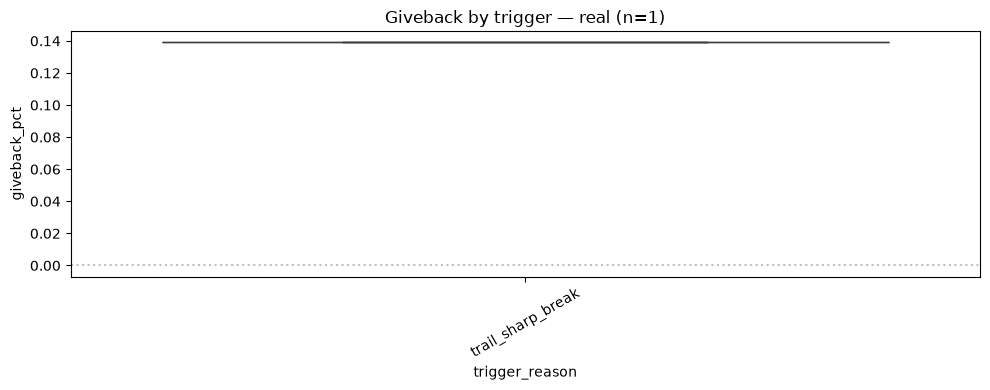

In [31]:
if df_fired.height:
    pdf = df_fired.to_pandas()
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(data=pdf, x="trigger_reason", y="giveback_pct", ax=ax)
    ax.tick_params(axis="x", rotation=30)
    ax.set_title(f"Giveback by trigger — {LEDGER} (n={df_fired.height})")
    ax.axhline(0, color="gray", ls=":", alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("no triggered rows in tape yet")


## Position trajectories

Set `SYMBOL` to focus (e.g. `INJ/USD`), or `None` for every position in the census.
`FULL=True` plots every beat; otherwise dense tapes are downsampled.


INJ/USD: 3 position(s) in census


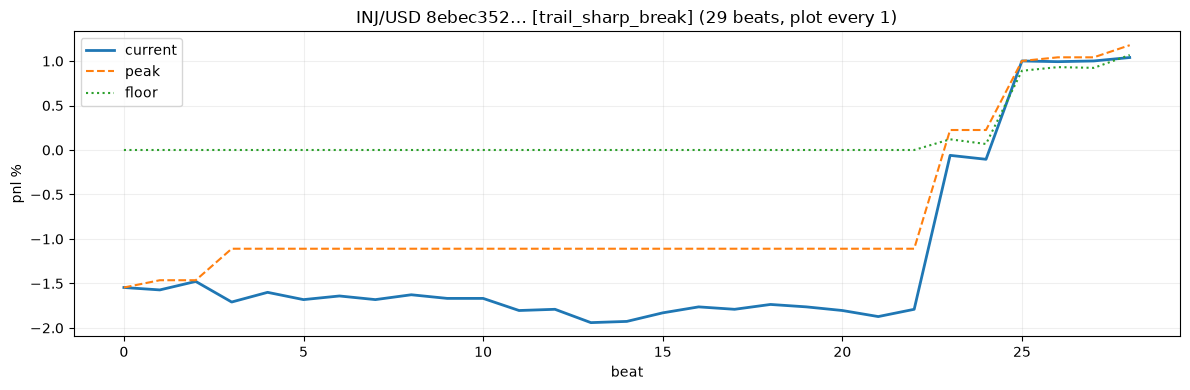

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""INJ/USD""",1794905432072601000,0,"""CRAWL""",-1.545532,-1.545532,0.0,"""""",0
"""INJ/USD""",1794905495035660000,0,"""SMOOTH""",-1.572766,-1.46383,0.0,"""""",0
"""INJ/USD""",1794905497903767000,0,"""CRAWL""",-1.477447,-1.46383,0.0,"""""",0
"""INJ/USD""",1794906131171659000,0,"""SMOOTH""",-1.708936,-1.109787,0.0,"""""",0
"""INJ/USD""",1794906132519362000,0,"""CRAWL""",-1.6,-1.109787,0.0,"""""",0
…,…,…,…,…,…,…,…,…
"""INJ/USD""",1794915183305958000,0,"""CRAWL""",-0.104461,0.224681,0.067405,"""""",0
"""INJ/USD""",1794915424367598000,1,"""CRAWL""",1.000851,1.000851,0.890553,"""""",0
"""INJ/USD""",1794915426476037000,0,"""CRAWL""",0.992876,1.041702,0.931404,"""""",0


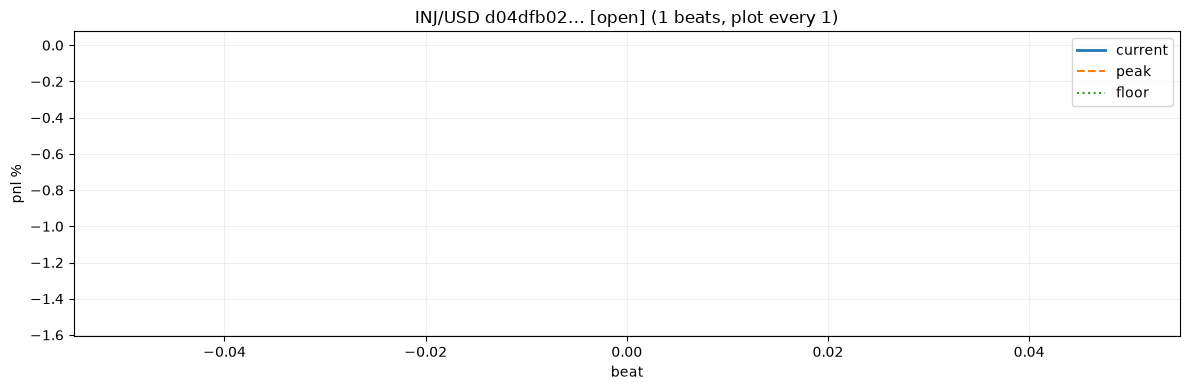

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""INJ/USD""",1794905254885930000,0,"""CRAWL""",-1.531915,-1.531915,0.0,"""""",0


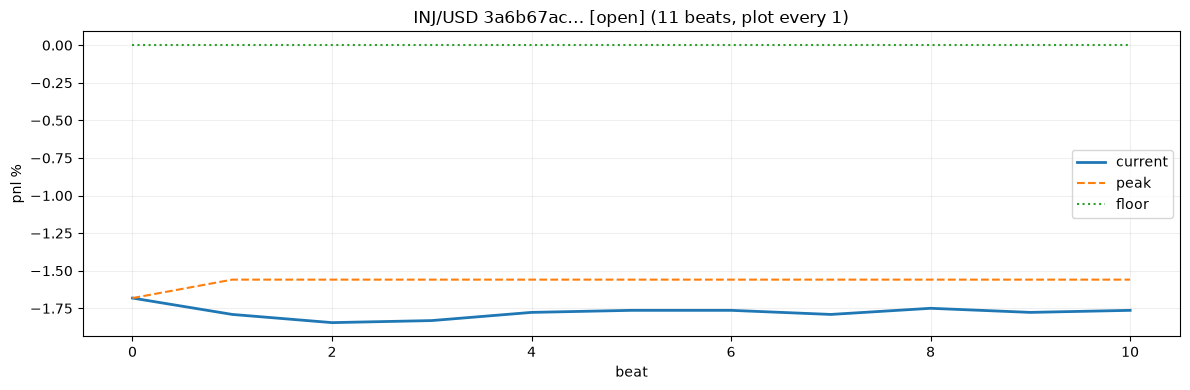

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""INJ/USD""",1794904507761368000,0,"""CRAWL""",-1.681702,-1.681702,0.0,"""""",0
"""INJ/USD""",1794904836796985000,0,"""SMOOTH""",-1.790638,-1.559149,0.0,"""""",0
"""INJ/USD""",1794904837251333000,0,"""CHAOS""",-1.845106,-1.559149,0.0,"""""",0
"""INJ/USD""",1794904837345750000,0,"""SMOOTH""",-1.831489,-1.559149,0.0,"""""",0
"""INJ/USD""",1794904843741516000,0,"""CHAOS""",-1.777021,-1.559149,0.0,"""""",0
…,…,…,…,…,…,…,…,…
"""INJ/USD""",1794904844287889000,0,"""CRAWL""",-1.763404,-1.559149,0.0,"""""",0
"""INJ/USD""",1794904867655601000,0,"""SMOOTH""",-1.790638,-1.559149,0.0,"""""",0
"""INJ/USD""",1794904878025368000,0,"""CRAWL""",-1.749787,-1.559149,0.0,"""""",0


In [32]:
from IPython.display import display

# SYMBOL comes from the snapshot cell; set FULL here for plot density.
FULL = True  # True = every beat; False = downsample dense tapes

df_plot = df_positions
if SYMBOL:
    df_plot = df_positions.filter(pl.col("symbol") == SYMBOL)
    print(f"{SYMBOL}: {df_plot.height} position(s) in census")
    if not df_plot.height:
        print("symbols in tape:", sorted(df_positions["symbol"].unique().to_list()))

if not df_plot.height:
    print("nothing to plot")
else:
    for row in df_plot.iter_rows(named=True):
        position_id = row["position_id"]
        traj_sql = f"""
        SELECT
            symbol,
            noted_at_ns,
            state,
            regime,
            current_pnl_pct,
            peak_pnl_pct,
            trailing_floor,
            trigger_reason,
            confirms
        FROM {STOPS_FROM}
        WHERE position_id = '{position_id}'
        ORDER BY noted_at_ns;
        """
        df_traj = con.sql(traj_sql).pl()
        if not df_traj.height:
            continue

        step = 1 if FULL else max(1, df_traj.height // 2000)
        pdf = df_traj.to_pandas().iloc[::step].reset_index(drop=True)
        pdf["t"] = range(len(pdf))

        reason = row["trigger_reason"] or "open"
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(pdf["t"], pdf["current_pnl_pct"], label="current", lw=2)
        ax.plot(pdf["t"], pdf["peak_pnl_pct"], label="peak", lw=1.5, ls="--")
        ax.plot(pdf["t"], pdf["trailing_floor"], label="floor", lw=1.5, ls=":")
        ax.set_title(
            f"{row['symbol']} {position_id[:8]}… [{reason}] "
            f"({df_traj.height} beats, plot every {step})"
        )
        ax.set_xlabel("beat (downsampled)" if step > 1 else "beat")
        ax.set_ylabel("pnl %")
        ax.legend()
        ax.grid(True, alpha=0.2)
        plt.tight_layout()
        plt.show()
        display(df_traj if FULL else df_traj.tail(20))
